In [1]:
!pip -q install seaborn scikit-learn scipy

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Please upload the Netflix CSV dataset.")

FILE_NAME = csv_files[0]
print("Using:", FILE_NAME)

Saving NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv to NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv
Using: NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv


In [3]:
df = pd.read_csv(FILE_NAME)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing %": (df.isna().mean().values * 100).round(2),
    "Unique Values": df.nunique().values
}))

Rows: 7787
Columns: 12


,Column,Data Type,Missing Values,Missing %,Unique Values
0,show_id,object,0,0.00,7787
1,type,object,0,0.00,2
2,title,object,0,0.00,7787
3,director,object,2389,30.68,4049
4,cast,object,718,9.22,6831
5,country,object,507,6.51,681
6,date_added,object,10,0.13,1565
7,release_year,int64,0,0.00,73
8,rating,object,7,0.09,14
9,duration,object,0,0.00,216


In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s7787,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nUnique values in type:")
display(df["type"].value_counts(dropna=False))

Duplicate rows: 0

Missing values:


,missing
director,2389
cast,718
country,507
date_added,10
rating,7
title,0
show_id,0
type,0
release_year,0
duration,0



Unique values in type:


,count
type,
Movie,5377
TV Show,2410


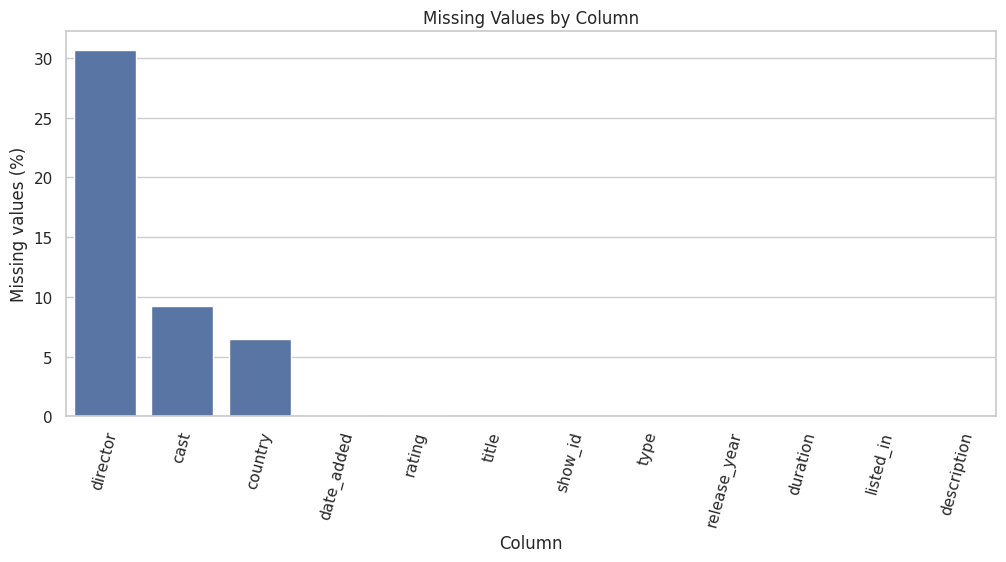

In [7]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=missing_pct.index, y=missing_pct.values)
plt.xticks(rotation=75)
plt.ylabel("Missing values (%)")
plt.xlabel("Column")
plt.title("Missing Values by Column")
plt.show()

In [8]:
data = df.copy()

text_categorical_cols = ["director", "cast", "country", "rating"]

for col in text_categorical_cols:
    data[col] = data[col].fillna("Unknown")

data["date_added"] = pd.to_datetime(
    data["date_added"],
    errors="coerce"
)

print("Duplicates after initial cleaning:", data.duplicated().sum())

Duplicates after initial cleaning: 0


In [9]:
data["date_added_year"] = data["date_added"].dt.year
data["date_added_month"] = data["date_added"].dt.month

# Extract numeric duration
data["duration_num"] = pd.to_numeric(
    data["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Duration unit
data["duration_unit"] = data["duration"].astype(str).str.extract(
    r"([A-Za-z]+)"
)[0].str.lower()

# Simple content age at the time it was added
data["content_age"] = data["date_added_year"] - data["release_year"]

display(data[[
    "title", "type", "release_year", "date_added_year",
    "duration", "duration_num", "duration_unit", "content_age"
]].head())

,title,type,release_year,date_added_year,duration,duration_num,duration_unit,content_age
0,3%,TV Show,2020,2020.0,4 Seasons,4,seasons,0.0
1,7:19,Movie,2016,2016.0,93 min,93,min,0.0
2,23:59,Movie,2011,2018.0,78 min,78,min,7.0
3,9,Movie,2009,2017.0,80 min,80,min,8.0
4,21,Movie,2008,2020.0,123 min,123,min,12.0


In [10]:
numeric_cols = ["release_year", "duration_num", "content_age"]

outlier_summary = []

for col in numeric_cols:
    s = data[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((s < lower) | (s > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(count)
    })

display(pd.DataFrame(outlier_summary))

,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
0,release_year,2013.0,2018.0,2005.5,2025.5,745
1,duration_num,2.0,106.0,-154.0,262.0,1
2,content_age,0.0,5.0,-7.5,12.5,806


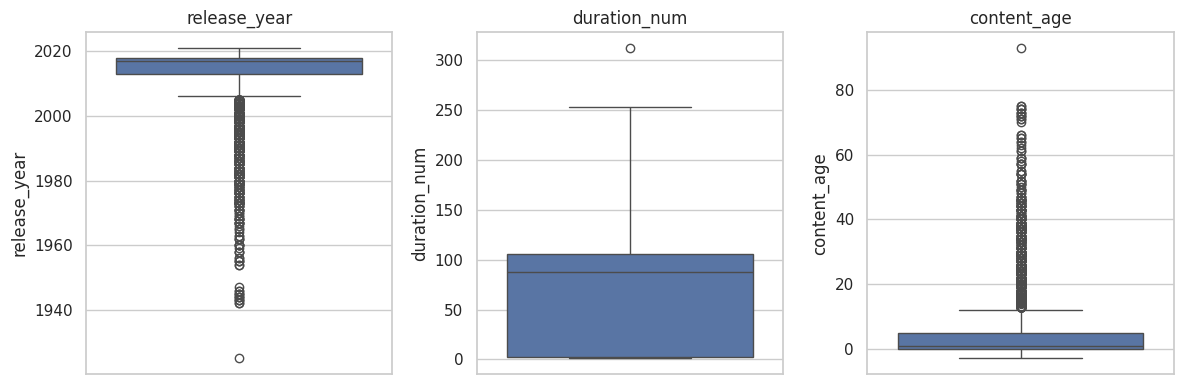

In [11]:
plt.figure(figsize=(12, 4))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

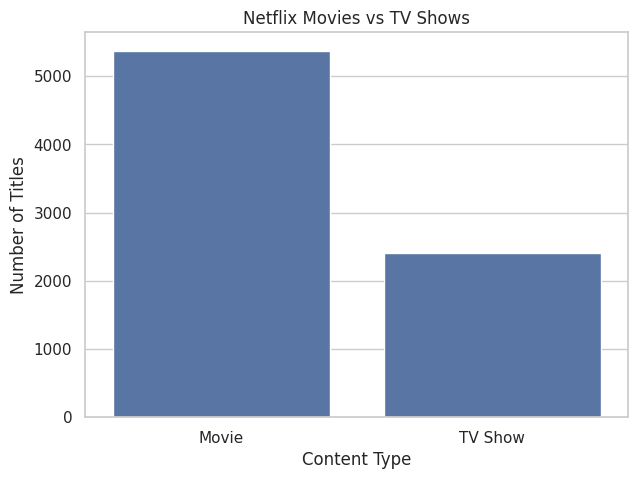

,count
type,
Movie,5377
TV Show,2410


In [12]:
type_counts = data["type"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=type_counts.index, y=type_counts.values)
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

display(type_counts.to_frame("count"))

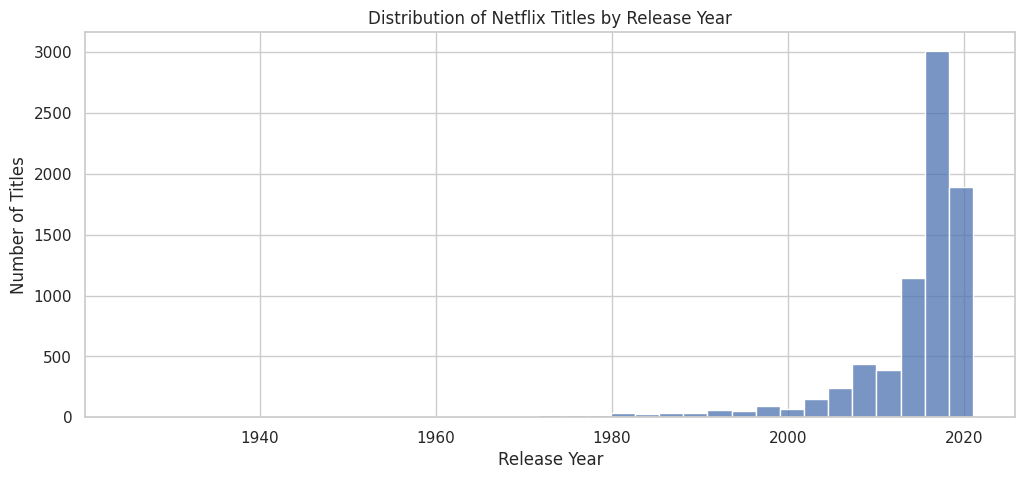

In [13]:
plt.figure(figsize=(12, 5))
sns.histplot(data=data, x="release_year", bins=35)
plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

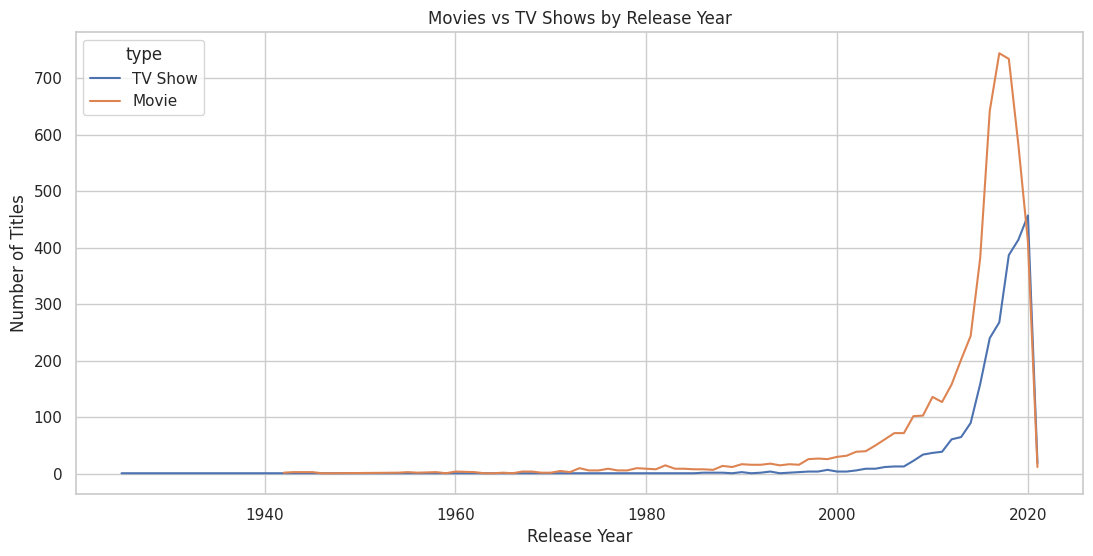

In [14]:
year_type = (
    data.groupby(["release_year", "type"])
        .size()
        .reset_index(name="count")
)

plt.figure(figsize=(13, 6))
sns.lineplot(
    data=year_type,
    x="release_year",
    y="count",
    hue="type"
)
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

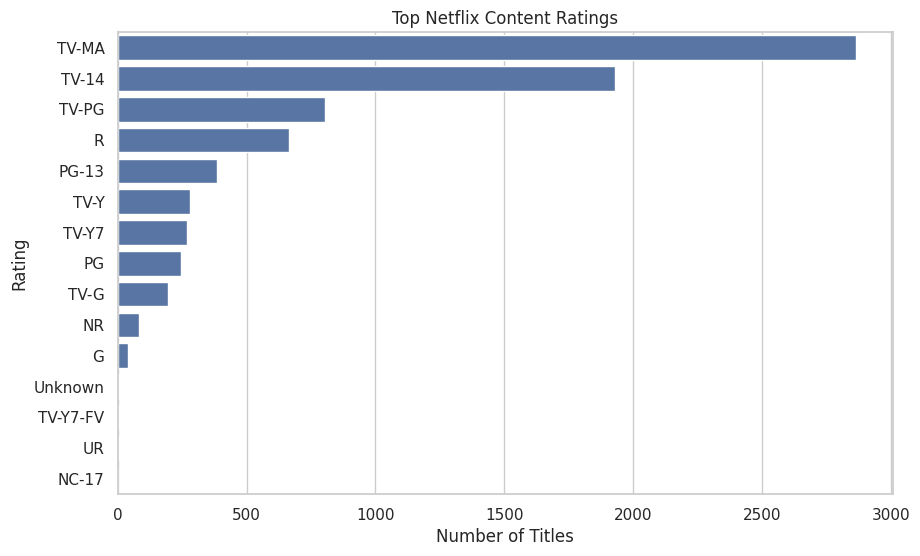

In [15]:
rating_counts = data["rating"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Top Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.show()

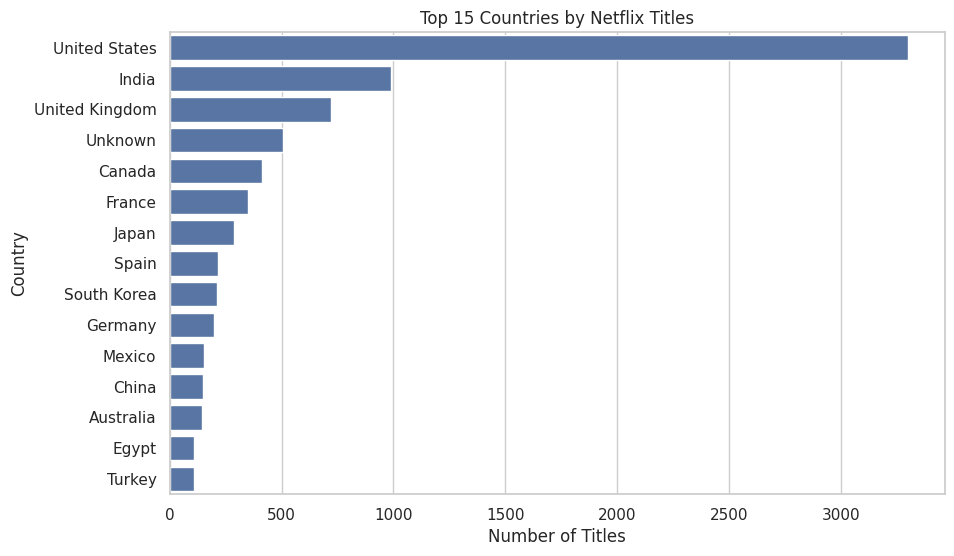

,titles
country,
United States,3297
India,990
United Kingdom,723
Unknown,507
Canada,412
France,349
Japan,287
Spain,215
South Korea,212


In [16]:
country_counts = (
    data["country"]
        .fillna("Unknown")
        .str.split(",")
        .explode()
        .str.strip()
        .replace("", np.nan)
        .dropna()
        .value_counts()
        .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top 15 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

display(country_counts.to_frame("titles"))

In [18]:
text_cols = ["title", "listed_in", "description"]

for col in text_cols:
    data[col] = data[col].fillna("Unknown").astype(str)

data["text_features"] = data[text_cols].agg(" ".join, axis=1)

data["text_features"] = (
    data["text_features"]
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

display(data[["title", "listed_in", "text_features"]].head())

,title,listed_in,text_features
0,3%,"International TV Shows, TV Dramas, TV Sci-Fi &...",3 international tv shows tv dramas tv sci fi f...
1,7:19,"Dramas, International Movies",7 19 dramas international movies after a devas...
2,23:59,"Horror Movies, International Movies",23 59 horror movies international movies when ...
3,9,"Action & Adventure, Independent Movies, Sci-Fi...",9 action adventure independent movies sci fi f...
4,21,Dramas,21 dramas a brilliant group of students become...


In [19]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=8000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(data["text_features"])

print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (7787, 8000)


In [20]:
svd = TruncatedSVD(
    n_components=100,
    random_state=RANDOM_STATE
)

X_svd = svd.fit_transform(X_tfidf)

explained = svd.explained_variance_ratio_.sum()

print("Reduced matrix shape:", X_svd.shape)
print(f"Variance captured by 100 SVD components: {explained:.2%}")

Reduced matrix shape: (7787, 100)
Variance captured by 100 SVD components: 17.89%


In [21]:
K_RANGE = range(2, 11)

inertias = []
silhouette_scores = []

for k in K_RANGE:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )
    labels = model.fit_predict(X_svd)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(
            X_svd,
            labels,
            sample_size=min(3000, len(data)),
            random_state=RANDOM_STATE
        )
    )

results_k = pd.DataFrame({
    "k": list(K_RANGE),
    "inertia": inertias,
    "silhouette": silhouette_scores
})

display(results_k)

,k,inertia,silhouette
0,2,1239.608649,0.149041
1,3,1197.644360,0.058311
2,4,1161.856889,0.064883
3,5,1136.632504,0.069302
4,6,1106.470415,0.063600
5,7,1083.245613,0.072897
6,8,1052.985355,0.072694
7,9,1025.168707,0.089935
8,10,1005.380360,0.100070


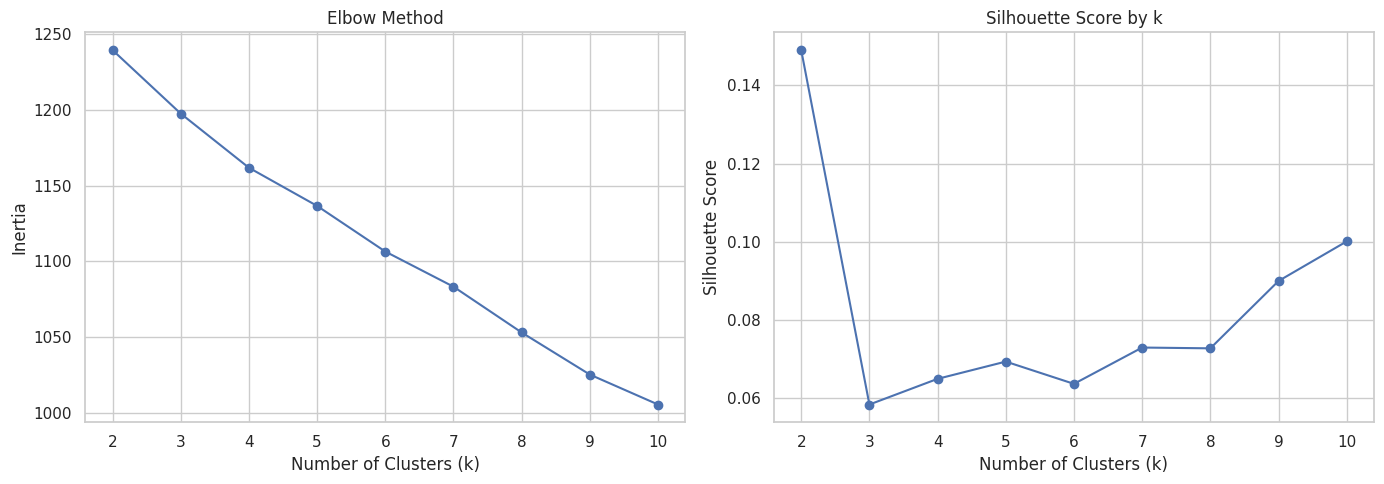

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(results_k["k"], results_k["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(results_k["k"], results_k["silhouette"], marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [23]:
N_CLUSTERS = 8

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

data["kmeans_cluster"] = kmeans.fit_predict(X_svd)

kmeans_silhouette = silhouette_score(
    X_svd,
    data["kmeans_cluster"],
    sample_size=min(3000, len(data)),
    random_state=RANDOM_STATE
)

print(f"K-Means silhouette score: {kmeans_silhouette:.4f}")
display(data["kmeans_cluster"].value_counts().sort_index().to_frame("titles"))

K-Means silhouette score: 0.0727


,titles
kmeans_cluster,
0,839
1,525
2,2420
3,1171
4,1102
5,381
6,848
7,501


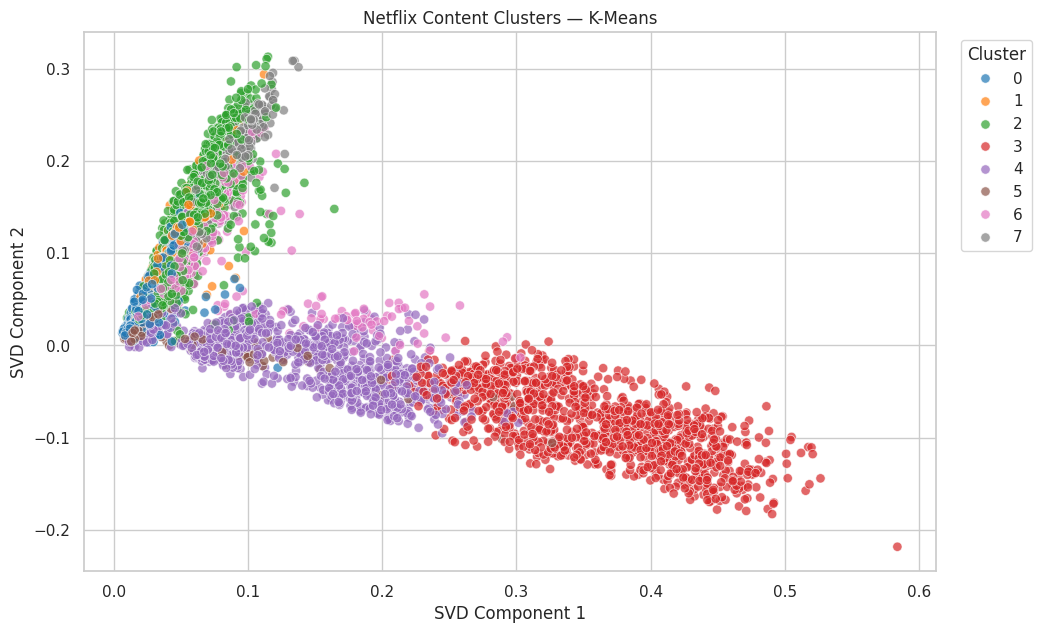

In [24]:
svd_2d = TruncatedSVD(
    n_components=2,
    random_state=RANDOM_STATE
)

X_2d = svd_2d.fit_transform(X_tfidf)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    x=X_2d[:, 0],
    y=X_2d[:, 1],
    hue=data["kmeans_cluster"],
    palette="tab10",
    s=45,
    alpha=0.7,
    legend="full"
)

plt.title("Netflix Content Clusters — K-Means")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [25]:
terms = tfidf.get_feature_names_out()
centroids = kmeans.cluster_centers_
order_centroids = centroids.argsort(axis=1)[:, ::-1]

cluster_keywords = {}

for cluster_id in range(N_CLUSTERS):
    top_terms = [
        terms[i]
        for i in order_centroids[cluster_id, :15]
    ]
    cluster_keywords[cluster_id] = top_terms

keywords_df = pd.DataFrame({
    "Cluster": list(cluster_keywords.keys()),
    "Top Terms": [", ".join(v) for v in cluster_keywords.values()]
})

display(keywords_df)

,Cluster,Top Terms
0,0,"101, 000 euros, 10 year, 10, 10 years, 000, 13..."
1,1,"000 years, 000 euros, 000 prize, 000, 10 years..."
2,2,"000 euros, 000, 007, 100 000, 11 year, 10, 12 ..."
3,3,"000, 100 000, 100, 11, 101, 10 years, 14 year,..."
4,4,"000, 10 year, 000 years, 000 prize, 10, 12 yea..."
5,5,"10, 000 years, 10 000, 10 years, 000, 000 euro..."
6,6,"000 prize, 000 euros, 000, 100, 100 years, 12 ..."
7,7,"000 euros, 10 000, 000, 11, 12 year, 10 years,..."


In [27]:
cluster_summary = []

for cluster_id in range(N_CLUSTERS):
    subset = data[data["kmeans_cluster"] == cluster_id]

    genres = (
        subset["listed_in"]
        .str.split(",")
        .explode()
        .str.strip()
        .value_counts()
        .head(5)
    )

    examples = subset["title"].head(5).tolist()

    cluster_summary.append({
        "Cluster": cluster_id,
        "Titles": len(subset),
        "Movies": int((subset["type"] == "Movie").sum()),
        "TV Shows": int((subset["type"] == "TV Show").sum()),
        "Top Categories": ", ".join(genres.index.tolist()),
        "Example Titles": " | ".join(examples)
    })

cluster_summary_df = pd.DataFrame(cluster_summary)

display(cluster_summary_df)

,Cluster,Titles,Movies,TV Shows,Top Categories,Example Titles
0,0,839,814,25,"Documentaries, International Movies, Music & M...","2,215 | '89 | (T)ERROR | #AnneFrank - Parallel..."
1,1,525,525,0,"Children & Family Movies, Comedies, Dramas, Mu...",48 Christmas Wishes | A 2nd Chance | A Babysit...
2,2,2420,2412,8,"Dramas, International Movies, Comedies, Indepe...",7:19 | 23:59 | 21 | 122 | 187
3,3,1171,0,1171,"International TV Shows, TV Dramas, Crime TV Sh...",3% | 46 | 1983 | 1994 | Feb-09
4,4,1102,11,1091,"Kids' TV, TV Comedies, Docuseries, Reality TV,...",​SAINT SEIYA: Knights of the Zodiac | (Un)Well...
5,5,381,331,50,"Stand-Up Comedy, Stand-Up Comedy & Talk Shows,...",A Little Help with Carol Burnett | A Russell P...
6,6,848,783,65,"Action & Adventure, International Movies, Dram...","9 | 3022 | ​Goli Soda 2 | Æon Flux | 10,000 B.C."
7,7,501,501,0,"Romantic Movies, International Movies, Dramas,...",#FriendButMarried | #FriendButMarried 2 | #Rox...


In [28]:
agg = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    linkage="ward"
)

data["agg_cluster"] = agg.fit_predict(X_svd)

agg_silhouette = silhouette_score(
    X_svd,
    data["agg_cluster"],
    sample_size=min(3000, len(data)),
    random_state=RANDOM_STATE
)

print(f"Agglomerative silhouette score: {agg_silhouette:.4f}")
display(data["agg_cluster"].value_counts().sort_index().to_frame("titles"))

Agglomerative silhouette score: 0.0751


,titles
agg_cluster,
0,3789
1,1110
2,759
3,669
4,366
5,453
6,304
7,337


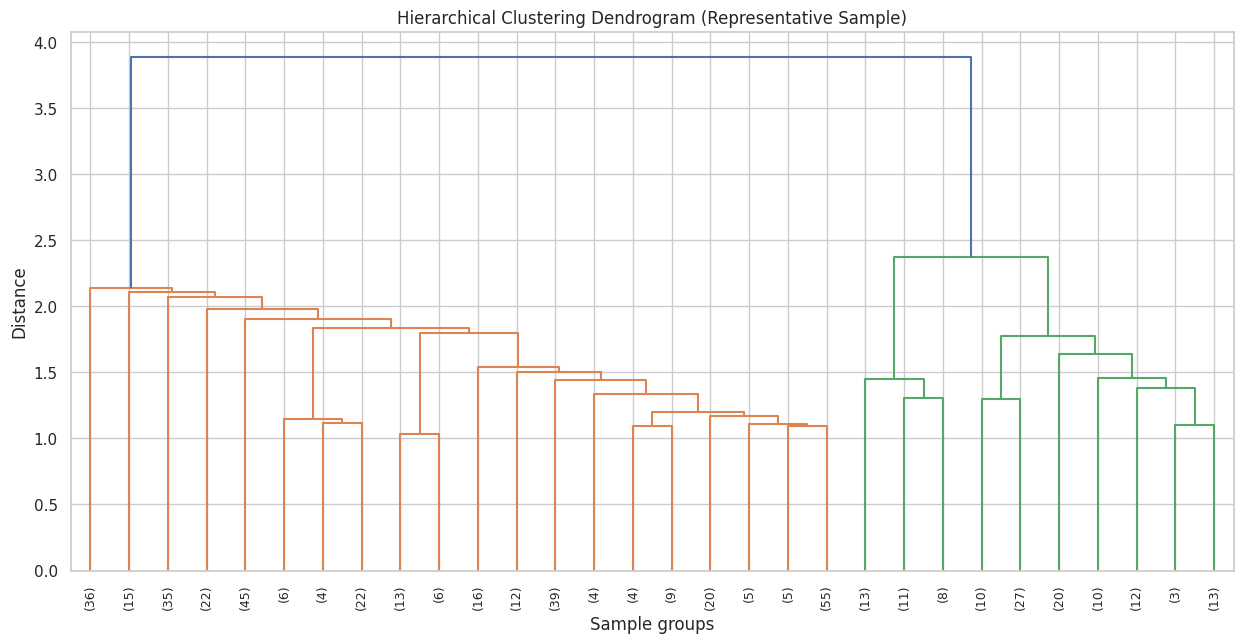

In [29]:
sample_n = min(500, len(data))
sample_idx = data.sample(sample_n, random_state=RANDOM_STATE).index

X_sample = X_svd[data.index.get_indexer(sample_idx)]

Z = linkage(X_sample, method="ward")

plt.figure(figsize=(15, 7))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)
plt.title("Hierarchical Clustering Dendrogram (Representative Sample)")
plt.xlabel("Sample groups")
plt.ylabel("Distance")
plt.show()

In [30]:
model_comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Clustering"],
    "Clusters": [N_CLUSTERS, N_CLUSTERS],
    "Silhouette Score": [kmeans_silhouette, agg_silhouette]
})

display(model_comparison.sort_values(
    "Silhouette Score",
    ascending=False
))

,Algorithm,Clusters,Silhouette Score
1,Agglomerative Clustering,8,0.075099
0,K-Means,8,0.072694


In [31]:
country_expanded = data[["title", "type", "country"]].copy()

country_expanded["country"] = (
    country_expanded["country"]
    .fillna("Unknown")
    .str.split(",")
)

country_expanded = country_expanded.explode("country")
country_expanded["country"] = country_expanded["country"].str.strip()

country_type_table = pd.crosstab(
    country_expanded["country"],
    country_expanded["type"]
)

top_countries = country_expanded["country"].value_counts().head(15).index

display(
    country_type_table.loc[
        country_type_table.index.intersection(top_countries)
    ].sort_values(
        by=country_type_table.columns.tolist(),
        ascending=False
    )
)

type,Movie,TV Show
country,,
United States,2431,866
India,915,75
United Kingdom,467,256
Canada,286,126
France,265,84
Unknown,230,277
Spain,158,57
Germany,157,42
Japan,103,184


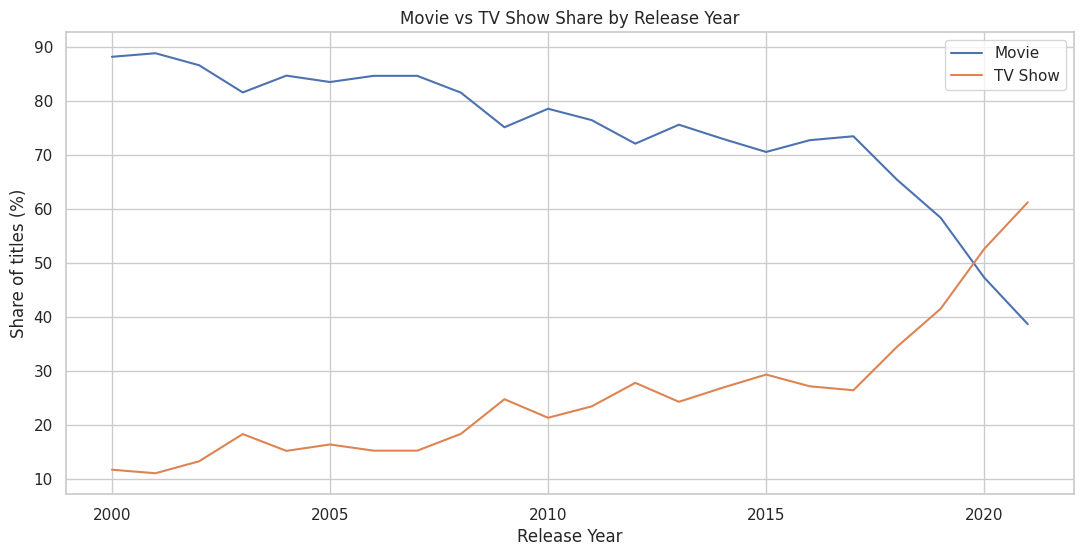

type,Movie,TV Show
release_year,,
2007,84.71,15.29
2008,81.60,18.40
2009,75.18,24.82
2010,78.61,21.39
2011,76.51,23.49
2012,72.15,27.85
2013,75.66,24.34
2014,73.05,26.95
2015,70.61,29.39


In [32]:
trend = pd.crosstab(
    data["release_year"],
    data["type"],
    normalize="index"
) * 100

trend = trend.loc[trend.index >= 2000]

plt.figure(figsize=(13, 6))

for col in trend.columns:
    plt.plot(
        trend.index,
        trend[col],
        label=col
    )

plt.title("Movie vs TV Show Share by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Share of titles (%)")
plt.legend()
plt.show()

display(trend.tail(15).round(2))

In [33]:
strategy_rows = []

for _, row in cluster_summary_df.iterrows():
    categories = row["Top Categories"].lower()

    if "stand-up comedy" in categories:
        strategy = "Use comedy-focused recommendations, specials collections, and comedy discovery rows."
    elif "horror" in categories:
        strategy = "Create horror/thriller collections and targeted seasonal recommendations."
    elif "children" in categories or "kids" in categories:
        strategy = "Use family-safe collections, age-appropriate discovery, and family viewing recommendations."
    elif "action" in categories or "adventure" in categories:
        strategy = "Promote action/adventure collections and high-engagement genre recommendation rows."
    elif "documentaries" in categories:
        strategy = "Create documentary and factual-content collections for interest-based discovery."
    elif "international" in categories or "dramas" in categories:
        strategy = "Use regional/language-aware recommendations and drama-focused content collections."
    else:
        strategy = "Use broader recommendation rows and test sub-segmentation using additional metadata."

    strategy_rows.append({
        "Cluster": row["Cluster"],
        "Strategy": strategy
    })

strategy_df = pd.DataFrame(strategy_rows)

display(
    cluster_summary_df.merge(
        strategy_df,
        on="Cluster"
    )[[
        "Cluster", "Titles", "Movies", "TV Shows",
        "Top Categories", "Strategy"
    ]]
)

,Cluster,Titles,Movies,TV Shows,Top Categories,Strategy
0,0,839,814,25,"Documentaries, International Movies, Music & M...",Create documentary and factual-content collect...
1,1,525,525,0,"Children & Family Movies, Comedies, Dramas, Mu...","Use family-safe collections, age-appropriate d..."
2,2,2420,2412,8,"Dramas, International Movies, Comedies, Indepe...",Use regional/language-aware recommendations an...
3,3,1171,0,1171,"International TV Shows, TV Dramas, Crime TV Sh...",Use regional/language-aware recommendations an...
4,4,1102,11,1091,"Kids' TV, TV Comedies, Docuseries, Reality TV,...","Use family-safe collections, age-appropriate d..."
5,5,381,331,50,"Stand-Up Comedy, Stand-Up Comedy & Talk Shows,...","Use comedy-focused recommendations, specials c..."
6,6,848,783,65,"Action & Adventure, International Movies, Dram...",Promote action/adventure collections and high-...
7,7,501,501,0,"Romantic Movies, International Movies, Dramas,...",Use regional/language-aware recommendations an...


In [34]:
OUTPUT_FILE = "netflix_clustered_results.csv"

In [35]:
data.to_csv(OUTPUT_FILE, index=False)

In [36]:
print("Saved:", OUTPUT_FILE)

files.download(OUTPUT_FILE)

Saved: netflix_clustered_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>